# 05 - Optimisation des hyperparamètres : k-NN et SVM (sections 2.2 et 2.4)

Dans ce notebook, l'objectif est d'entraîner et d'optimiser deux modèles fondés sur des distances : le k-NN et le SVM.

**Méthode commune à tout le groupe :** validation croisée stratifiée à 5 plis (`StratifiedKFold`), métrique F1, recherche sur le train uniquement. Le jeu de test n'est utilisé qu'au notebook 04.

In [1]:
import sys
from pathlib import Path

# Remonte jusqu'à la racine du projet (le dossier qui contient src/), quel que soit le dossier de lancement
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

from src.load_data import load_wine_data, make_binary_target, split_data
from src.preprocess import clean_data
from src.models import (
    KNN_GRID, SVM_DISTRIBUTIONS, knn, svm, load_selected_features, save_model,
)

from src.tuning import run_grid_search, run_random_search
from src.evaluate import train_vs_cv_scores

## 1. Données et variables retenues

In [2]:
df = make_binary_target(clean_data(load_wine_data()))
X_train, X_test, y_train, y_test = split_data(df)
features = load_selected_features()

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Variables retenues (notebook 02) :", features)

Lignes supprimées (doublons ou NA) : 1177
Train : (4256, 12) | Test : (1064, 12)
Variables retenues (notebook 02) : ['volatile acidity', 'residual sugar', 'density', 'alcohol']


## 2. k-NN (k plus proches voisins)

### 2.1 Modèle par défaut (k = 5, vote uniforme, distance euclidienne)

In [3]:
pd.Series(train_vs_cv_scores(knn(features), X_train, y_train)).round(3)

train             0.585
validation        0.393
validation_std    0.023
ecart             0.192
dtype: float64

### 2.2 Grid Search sur k, la pondération, la distance et le jeu de variables


In [4]:
knn_search = run_grid_search(knn(features), KNN_GRID, X_train, y_train)

print("Meilleurs hyperparamètres :", knn_search.best_params_)
print("F1 moyen en validation croisée :", round(knn_search.best_score_, 3))

Meilleurs hyperparamètres : {'model__n_neighbors': 3, 'model__p': 1, 'model__weights': 'distance'}
F1 moyen en validation croisée : 0.427


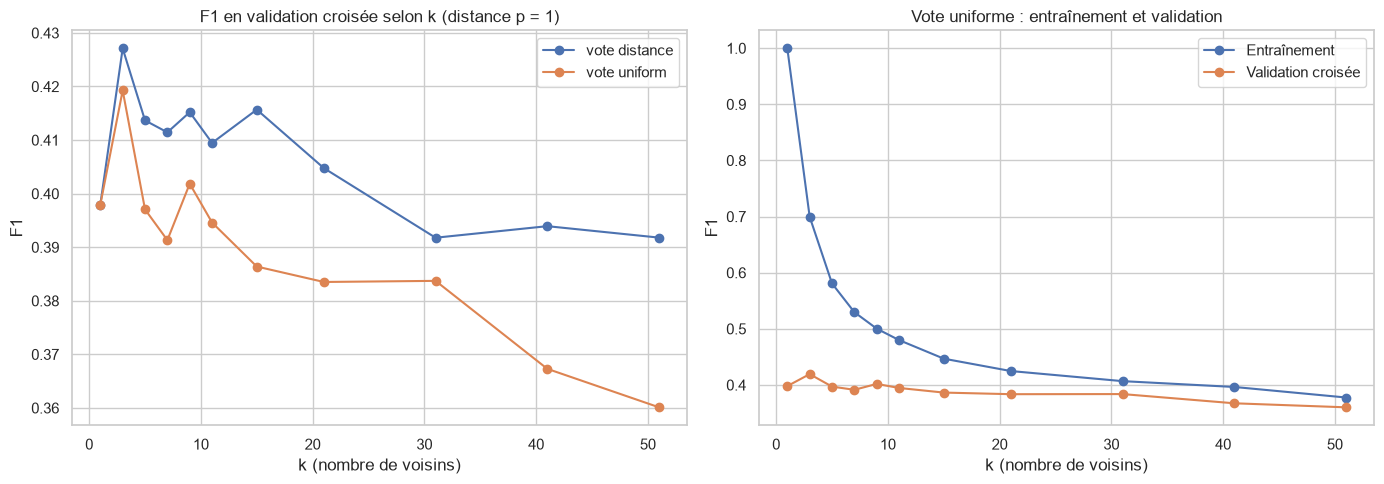

,k,param_model__weights,param_model__p,mean_train_score,mean_test_score,std_test_score
5,3,distance,1,1.000,0.427,0.025
4,3,uniform,1,0.699,0.419,0.027
7,3,distance,2,1.000,0.416,0.029
25,15,distance,1,1.000,0.416,0.020
17,9,distance,1,1.000,0.415,0.030
9,5,distance,1,1.000,0.414,0.035
6,3,uniform,2,0.689,0.412,0.031
13,7,distance,1,1.000,0.411,0.035


In [5]:
knn_cv = pd.DataFrame(knn_search.cv_results_)
knn_cv["k"] = knn_cv["param_model__n_neighbors"].astype(int)
best_p = knn_search.best_params_["model__p"]
sub = knn_cv[knn_cv["param_model__p"] == best_p]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for w, g in sub.groupby("param_model__weights"):
    axes[0].plot(g["k"], g["mean_test_score"], "o-", label=f"vote {w}")
axes[0].set(title=f"F1 en validation croisée selon k (distance p = {best_p})", xlabel="k (nombre de voisins)", ylabel="F1")
axes[0].legend()

uni = sub[sub["param_model__weights"] == "uniform"]
axes[1].plot(uni["k"], uni["mean_train_score"], "o-", label="Entraînement")
axes[1].plot(uni["k"], uni["mean_test_score"], "o-", label="Validation croisée")
axes[1].set(title="Vote uniforme : entraînement et validation", xlabel="k (nombre de voisins)", ylabel="F1")
axes[1].legend()
plt.tight_layout()
plt.show()

cols = ["k", "param_model__weights", "param_model__p", "mean_train_score", "mean_test_score", "std_test_score"]
knn_cv.sort_values("mean_test_score", ascending=False)[cols].head(8).round(3)

### 2.3 Ajustement du seuil de décision

In [6]:
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from src.models import make_pipeline
from src.tuning import CV

knn_tuned = TunedThresholdClassifierCV(
    make_pipeline(KNeighborsClassifier(p=best_p), features),
    scoring="f1", cv=CV,
)
knn_tuned_grid = {
    "estimator__model__n_neighbors": [5, 9, 15, 21, 31, 41, 51, 71, 101],
    "estimator__model__weights": ["uniform", "distance"],
}
knn_t_search = run_grid_search(knn_tuned, knn_tuned_grid, X_train, y_train)

print("Meilleurs hyperparamètres :", knn_t_search.best_params_)
print("F1 moyen en validation croisée :", round(knn_t_search.best_score_, 3))

Meilleurs hyperparamètres : {'estimator__model__n_neighbors': 101, 'estimator__model__weights': 'distance'}
F1 moyen en validation croisée : 0.54


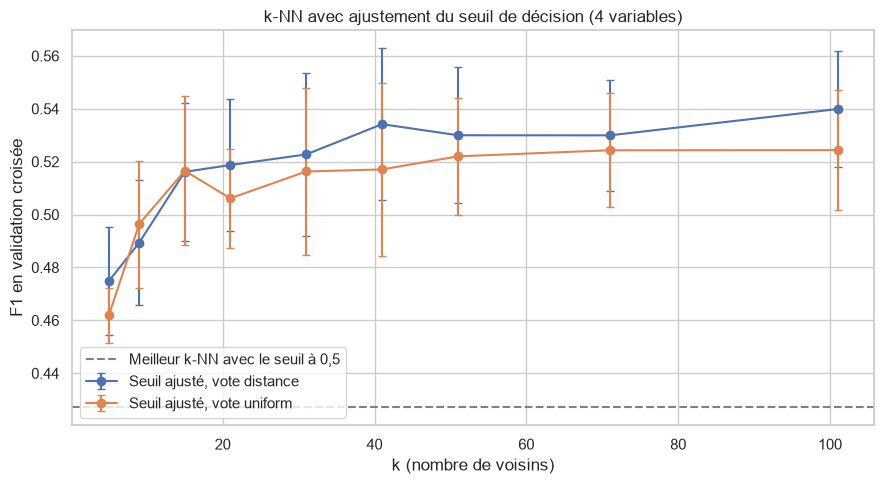

,k,param_estimator__model__weights,mean_train_score,mean_test_score,std_test_score
17,101,distance,1.000,0.540,0.022
11,41,distance,1.000,0.534,0.029
13,51,distance,1.000,0.530,0.026
15,71,distance,1.000,0.530,0.021
16,101,uniform,0.532,0.524,0.023
14,71,uniform,0.534,0.524,0.021
9,31,distance,1.000,0.523,0.031
12,51,uniform,0.542,0.522,0.022


In [7]:
knn_t_cv = pd.DataFrame(knn_t_search.cv_results_)
knn_t_cv["k"] = knn_t_cv["param_estimator__model__n_neighbors"].astype(int)

plt.figure(figsize=(9, 5))
for w, g in knn_t_cv.groupby("param_estimator__model__weights"):
    plt.errorbar(g["k"], g["mean_test_score"], yerr=g["std_test_score"], fmt="o-", capsize=3, label=f"Seuil ajusté, vote {w}")
plt.axhline(knn_search.best_score_, ls="--", color="grey", label="Meilleur k-NN avec le seuil à 0,5")
plt.xlabel("k (nombre de voisins)")
plt.ylabel("F1 en validation croisée")
plt.title("k-NN avec ajustement du seuil de décision (4 variables)")
plt.legend()
plt.tight_layout()
plt.show()

cols = ["k", "param_estimator__model__weights", "mean_train_score", "mean_test_score", "std_test_score"]
knn_t_cv.sort_values("mean_test_score", ascending=False)[cols].head(8).round(3)

In [8]:
from sklearn.base import clone

best = knn_t_cv.loc[knn_t_cv["mean_test_score"].idxmax()]
candidates = knn_t_cv[knn_t_cv["mean_test_score"] >= best["mean_test_score"] - best["std_test_score"]]
uniform = candidates[candidates["param_estimator__model__weights"] == "uniform"]
chosen = (uniform if len(uniform) else candidates).sort_values("k").iloc[-1]

knn_final = clone(knn_tuned).set_params(
    estimator__model__n_neighbors=int(chosen["k"]),
    estimator__model__weights=chosen["param_estimator__model__weights"],
).fit(X_train, y_train)

print("Réglage retenu : k =", int(chosen["k"]), "| vote", chosen["param_estimator__model__weights"],
      "| F1 validation =", round(chosen["mean_test_score"], 3))
print("Seuil optimal :", round(knn_final.best_threshold_, 3))
pd.Series(train_vs_cv_scores(knn_final, X_train, y_train)).round(3)

Réglage retenu : k = 101 | vote uniform | F1 validation = 0.524
Seuil optimal : 0.234


train             0.532
validation        0.524
validation_std    0.023
ecart             0.007
dtype: float64

In [9]:
save_model(knn_final, "knn")

## 3. SVM (machine à vecteurs de support)

### 3.1 Modèles par défaut (C = 1, gamma = "scale", class_weight = "balanced")

In [10]:
svm_base = pd.DataFrame({
    "linéaire, balanced": train_vs_cv_scores(svm(features).set_params(model__kernel="linear"), X_train, y_train),
    "RBF, balanced": train_vs_cv_scores(svm(features), X_train, y_train),
    "RBF, sans class_weight": train_vs_cv_scores(svm(features).set_params(model__class_weight=None), X_train, y_train),
}).T
svm_base.round(3)

,train,validation,validation_std,ecart
"linéaire, balanced",0.524,0.523,0.014,0.001
"RBF, balanced",0.525,0.516,0.013,0.008
"RBF, sans class_weight",0.304,0.298,0.024,0.006


### 3.2 Random Search sur le noyau, C et gamma

In [11]:
svm_search = run_random_search(svm(features), SVM_DISTRIBUTIONS, X_train, y_train, n_iter=60)

print("Meilleurs hyperparamètres :", svm_search.best_params_)
print("F1 moyen en validation croisée :", round(svm_search.best_score_, 3))
pd.Series(train_vs_cv_scores(svm_search.best_estimator_, X_train, y_train)).round(3)

Meilleurs hyperparamètres : {'model__C': np.float64(10.90747583515769), 'model__gamma': np.float64(0.0007122305833333872), 'model__kernel': 'rbf'}
F1 moyen en validation croisée : 0.527


train             0.525
validation        0.527
validation_std    0.012
ecart            -0.001
dtype: float64

Tirages par noyau et meilleur F1 obtenu :
                     count    max
param_model__kernel              
linear                  32  0.526
rbf                     28  0.527


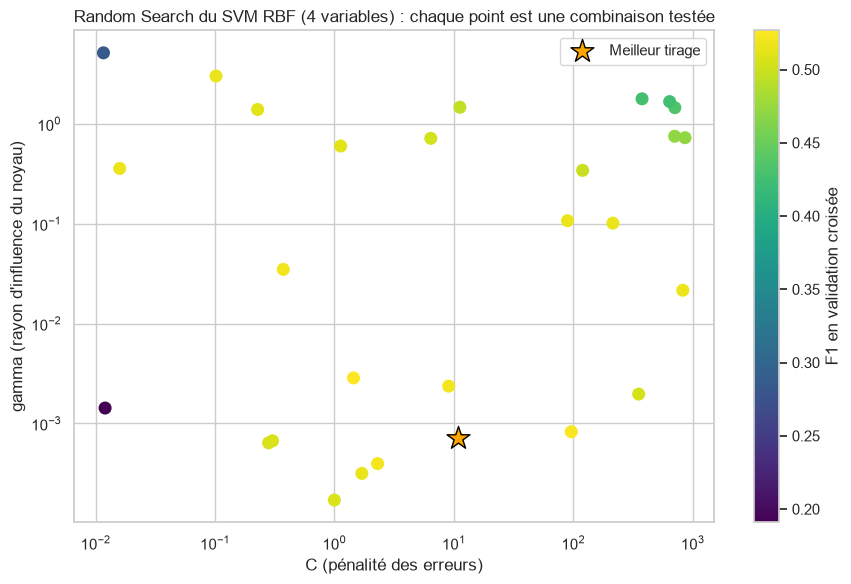

In [12]:
svm_cv = pd.DataFrame(svm_search.cv_results_)
svm_cv["C"] = svm_cv["param_model__C"].astype(float)
svm_cv["gamma"] = pd.to_numeric(svm_cv["param_model__gamma"], errors="coerce")

print("Tirages par noyau et meilleur F1 obtenu :")
print(svm_cv.groupby("param_model__kernel")["mean_test_score"].agg(["count", "max"]).round(3))

rbf = svm_cv[svm_cv["param_model__kernel"] == "rbf"]
best = svm_search.best_params_
plt.figure(figsize=(9, 6))
sc = plt.scatter(rbf["C"], rbf["gamma"], c=rbf["mean_test_score"], cmap="viridis", s=70)
plt.colorbar(sc, label="F1 en validation croisée")
if best["model__kernel"] == "rbf":
    plt.scatter(best["model__C"], best["model__gamma"], marker="*", s=300, color="orange", edgecolor="black", label="Meilleur tirage")
    plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("C (pénalité des erreurs)")
plt.ylabel("gamma (rayon d'influence du noyau)")
plt.title("Random Search du SVM RBF (4 variables) : chaque point est une combinaison testée")
plt.tight_layout()
plt.show()

In [13]:
save_model(svm_search.best_estimator_, "svm")

## 4. Grid Search ou Random Search : comparaison des deux méthodes



In [14]:
import time

grid_svm = {
    "model__kernel": ["rbf"],
    "model__C": np.logspace(-2, 3, 8),
    "model__gamma": np.logspace(-4, 1, 8),
}
dist_svm = SVM_DISTRIBUTIONS[0]

start = time.perf_counter()
grid_res = run_grid_search(svm(features), grid_svm, X_train, y_train)
grid_time = time.perf_counter() - start

start = time.perf_counter()
rand_res = run_random_search(svm(features), dist_svm, X_train, y_train, n_iter=16)
rand_time = time.perf_counter() - start

pd.DataFrame({
    "Grid Search (8 × 8)": {"combinaisons": 64, "meilleur F1": round(grid_res.best_score_, 3), "temps (s)": round(grid_time, 1)},
    "Random Search": {"combinaisons": 16, "meilleur F1": round(rand_res.best_score_, 3), "temps (s)": round(rand_time, 1)},
}).T

,combinaisons,meilleur F1,temps (s)
Grid Search (8 × 8),64.0,0.526,24.6
Random Search,16.0,0.527,5.7


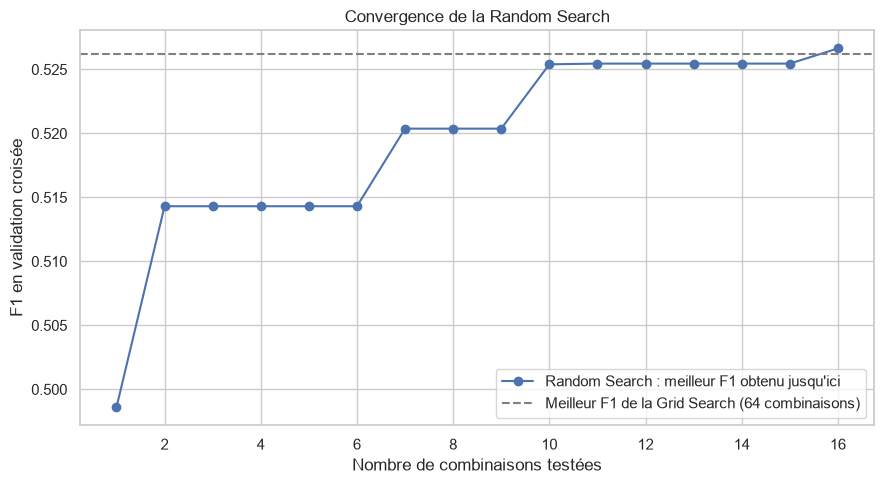

In [15]:
best_so_far = pd.DataFrame(rand_res.cv_results_)["mean_test_score"].cummax()

plt.figure(figsize=(9, 5))
plt.plot(range(1, 17), best_so_far, "o-", label="Random Search : meilleur F1 obtenu jusqu'ici")
plt.axhline(grid_res.best_score_, ls="--", color="grey", label="Meilleur F1 de la Grid Search (64 combinaisons)")
plt.xlabel("Nombre de combinaisons testées")
plt.ylabel("F1 en validation croisée")
plt.title("Convergence de la Random Search")
plt.legend()
plt.tight_layout()
plt.show()